# Segmentacja semantyczna pęknięć — DeepCrack
**Projekt:** Wykrywanie uszkodzeń obiektów budowlanych
**Problem:** segmentacja semantyczna binarna (rysa / tło)
**Zbiór:** DeepCrack — 537 zdjęć pęknięć betonu i asfaltu z maskami pikselowymi
Źródło: https://github.com/yhlleo/DeepCrack · Liu i in., *DeepCrack: A deep hierarchical feature learning architecture for crack segmentation*, Neurocomputing 2019
Licencja: użycie ograniczone do niekomercyjnych badań i celów edukacyjnych.

**Eksperymenty:** 3 architektury × 2 konfiguracje = 6 treningów

| | Konfiguracja 1 (wspólna) | Konfiguracja 2 (jedna zmiana) |
|---|---|---|
| U-Net (ResNet34) | enkoder pretrenowany na ImageNet | trening od zera |
| DeepLabV3+ (ResNet34) | enkoder pretrenowany na ImageNet | trening od zera |
| FPN (ResNet34) | enkoder pretrenowany na ImageNet | trening od zera |

Wszystko poza wagami startowymi enkodera jest identyczne: seed, podział danych, rozdzielczość, augmentacja, liczba epok, optymalizator, funkcja straty, metryki.

**Środowisko:** Google Colab, GPU NVIDIA T4.

## 0. Hipotezy (sformułowane przed treningami)

**Zmiana w konfiguracji 2:** enkoder ResNet34 trenowany od zera zamiast enkodera pretrenowanego na ImageNet. Wszystkie pozostałe warunki są identyczne: seed 42, podział 240/60/237, wycinki 384×384, augmentacja, 40 epok, AdamW (lr 3e-4), Dice + BCE.

**H1 – efekt pretreningu (główna hipoteza):**
Dla wszystkich trzech architektur model z pretrenowanym enkoderem osiągnie wyższe IoU klasy „rysa” na zbiorze testowym niż model trenowany od zera. Spodziewamy się różnicy rzędu 5–15 punktów procentowych.
*Uzasadnienie:* zbiór treningowy jest mały (240 obrazów), a enkoder ma ok. 21 mln parametrów. Bez pretreningu sieć musi nauczyć się podstawowych cech (krawędzie, kontrasty, tekstury) wyłącznie z tych danych. Pretrenowany enkoder ma je od startu, a cienka, ciemna linia na jasnym tle to właśnie cecha niskiego poziomu, którą sieci uczą się na ImageNet.

**H2 – efekt zależy od architektury:**
Spadek po rezygnacji z pretreningu będzie największy dla DeepLabV3+.
*Uzasadnienie:* U-Net i FPN łączą cechy z kilku poziomów enkodera przez połączenia skrótowe, więc dekoder częściowo kompensuje słabszy enkoder. DeepLabV3+ korzysta głównie z cech z głębokich warstw (oraz jednego płytkiego połączenia), więc jakość enkodera ma dla niego większe znaczenie.

**H3 – porównanie architektur w konfiguracji 1:**
U-Net i FPN uzyskają wyższe IoU niż DeepLabV3+.
*Uzasadnienie:* rysy mają szerokość od 1 px. Dekoder U-Neta odtwarza maskę z pełnej rozdzielczości dzięki połączeniom skrótowym na każdym poziomie, a DeepLabV3+ przewiduje w rozdzielczości 1/4 i skaluje wynik w górę, co rozmywa najcieńsze rysy.

**H4 – zbieżność i rodzaj błędów:**
Modele trenowane od zera będą zbiegać wolniej (wyższy val loss i niższe val IoU w pierwszych epokach). Ich błędy będą dotyczyć głównie przeoczonych cienkich rys, więc spodziewamy się przede wszystkim niższego recall, a nie precision.

**Jak zweryfikujemy:** tabela Δ IoU i Δ F1 (sekcja 10a) dla H1 i H2, test IoU w konfiguracji 1 (sekcja 10) dla H3, a krzywe uczenia (sekcja 11) oraz precision/recall dla H4.

## 1. Instalacja i importy

In [1]:
!pip install -q segmentation-models-pytorch==0.6.0 albumentations==2.0.8

In [2]:
import os, time, random, json, glob, zipfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

print("torch", torch.__version__, "| smp", smp.__version__, "| albumentations", A.__version__)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

torch 2.14.1+cu130 | smp 0.6.0 | albumentations 2.0.8
Device: cuda Tesla T4


## 2. Ustawienia projektu i powtarzalność

In [3]:
SEED = 42

def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

seed_everything()

# Zapis wyników na Google Drive (żeby nie zniknęły po rozłączeniu Colaba).
USE_DRIVE = True
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/BudownictwoAI/deepcrack_runs")
    except ImportError:
        OUT_DIR = Path("runs")
else:
    OUT_DIR = Path("runs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Wyniki zapisywane w:", OUT_DIR)

Mounted at /content/drive
Wyniki zapisywane w: /content/drive/MyDrive/BudownictwoAI/deepcrack_runs


## 3. Pobranie zbioru DeepCrack

In [4]:
DATA_ROOT = Path("data/DeepCrack")
if not (DATA_ROOT / "train_img").exists():
    !git clone -q --depth 1 https://github.com/yhlleo/DeepCrack.git /tmp/DeepCrack_repo
    with zipfile.ZipFile("/tmp/DeepCrack_repo/dataset/DeepCrack.zip") as z:
        z.extractall(DATA_ROOT)

for sub in ["train_img", "train_lab", "test_img", "test_lab"]:
    print(f"{sub:10s}", len(os.listdir(DATA_ROOT / sub)))

train_img  300
train_lab  300
test_img   237
test_lab   237


## 4. Podział danych: train 240 / val 60 / test 237
Oficjalny podział autorów: 300 train + 237 test. Z oficjalnego zbioru treningowego losujemy (seed 42) 60 obrazów do walidacji. Zbiór testowy pozostaje nietknięty aż do końcowej ewaluacji.
Podział zapisujemy do CSV — wszystkie 6 treningów używa dokładnie tych samych plików.

In [5]:
def list_pairs(img_dir, lab_dir):
    pairs = []
    for f in sorted(os.listdir(img_dir)):
        stem = os.path.splitext(f)[0]
        lab = lab_dir / f"{stem}.png"
        assert lab.exists(), f"Brak maski dla {f}"   # obraz i maska parowane po nazwie pliku
        pairs.append((str(img_dir / f), str(lab)))
    return pairs

SPLIT_CSV = OUT_DIR / "split.csv"
if SPLIT_CSV.exists():
    split_df = pd.read_csv(SPLIT_CSV)
    split_df["image"] = split_df["image"].apply(lambda p: str(DATA_ROOT / Path(p).parent.name / Path(p).name))
    split_df["mask"] = split_df["mask"].apply(lambda p: str(DATA_ROOT / Path(p).parent.name / Path(p).name))
    print("Wczytano istniejący podział:", SPLIT_CSV)
else:
    train_pairs = list_pairs(DATA_ROOT / "train_img", DATA_ROOT / "train_lab")
    test_pairs = list_pairs(DATA_ROOT / "test_img", DATA_ROOT / "test_lab")
    rng = np.random.RandomState(SEED)
    idx = rng.permutation(len(train_pairs))
    val_idx = set(idx[:60].tolist())
    rows = []
    for i, (im, m) in enumerate(train_pairs):
        rows.append({"image": im, "mask": m, "split": "val" if i in val_idx else "train"})
    for im, m in test_pairs:
        rows.append({"image": im, "mask": m, "split": "test"})
    split_df = pd.DataFrame(rows)
    split_df.to_csv(SPLIT_CSV, index=False)

print(split_df["split"].value_counts())

split
train    240
test     237
val       60
Name: count, dtype: int64


### 4a. Statystyki zbioru

In [6]:
stats = []
for _, r in split_df.iterrows():
    m = cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE)
    stats.append({"split": r["split"], "h": m.shape[0], "w": m.shape[1],
                  "crack_frac": (m > 127).mean(), "unique_vals": len(np.unique(m))})
stats_df = pd.DataFrame(stats)
print("Rozmiary obrazów:\n", stats_df.groupby(["h", "w"]).size())
print("\nUdział pikseli rysy [%] wg podziału:")
print((stats_df.groupby("split")["crack_frac"].agg(["mean", "min", "max"]) * 100).round(2))
print(f"\nCały zbiór: {stats_df['crack_frac'].mean()*100:.2f}% pikseli to rysa -> silne niezbalansowanie klas")
print("Liczba różnych wartości w maskach (max):", stats_df["unique_vals"].max())

Rozmiary obrazów:
 h    w  
384  544    490
544  384     47
dtype: int64

Udział pikseli rysy [%] wg podziału:
       mean   min    max
split                   
test   4.33  0.69  19.25
train  2.95  0.26  19.94
val    2.75  0.29  16.47

Cały zbiór: 3.54% pikseli to rysa -> silne niezbalansowanie klas
Liczba różnych wartości w maskach (max): 2


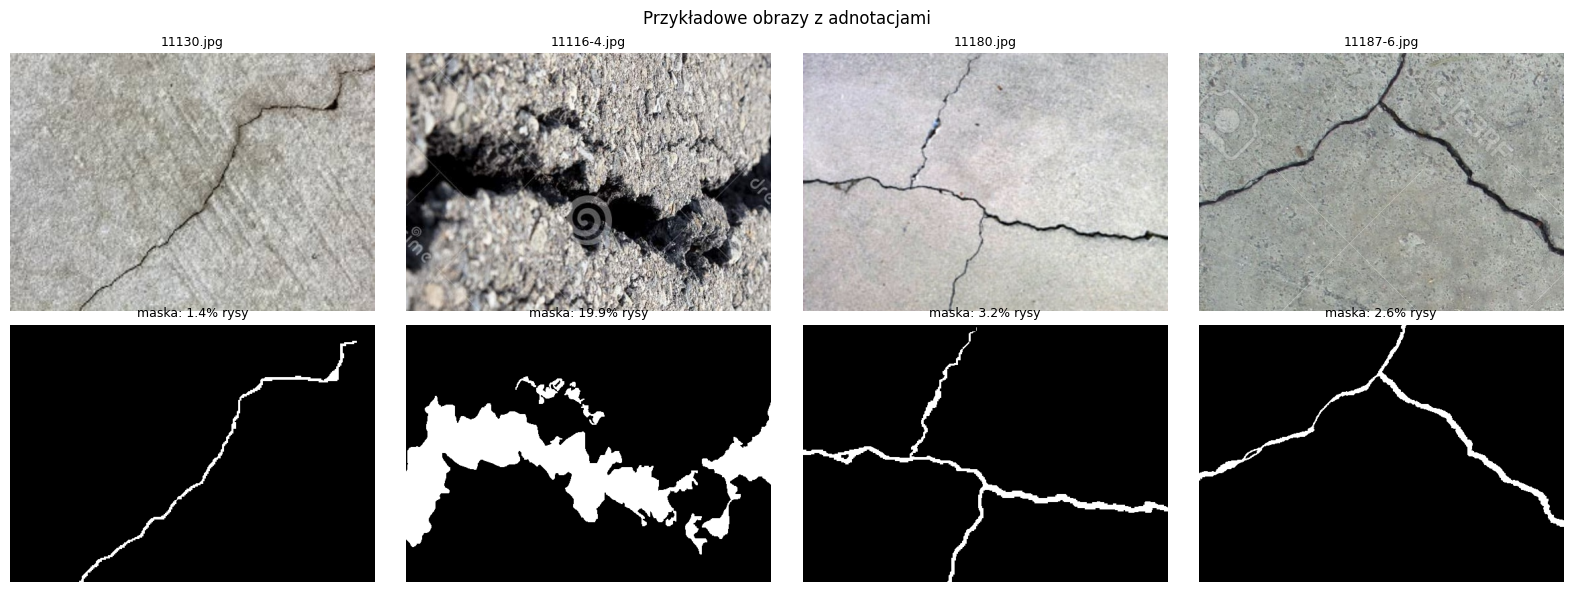

In [7]:
def show_samples(df, n=4, title="Przykładowe obrazy z adnotacjami"):
    sub = df.sample(n, random_state=SEED)
    fig, ax = plt.subplots(2, n, figsize=(4 * n, 6))
    for j, (_, r) in enumerate(sub.iterrows()):
        img = cv2.cvtColor(cv2.imread(r["image"]), cv2.COLOR_BGR2RGB)
        m = cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE)
        ax[0, j].imshow(img); ax[0, j].set_title(Path(r["image"]).name, fontsize=9)
        ax[1, j].imshow(m, cmap="gray"); ax[1, j].set_title(f"maska: {(m>127).mean()*100:.1f}% rysy", fontsize=9)
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle(title); plt.tight_layout()
    fig.savefig(OUT_DIR / "dataset_samples.png", dpi=150); plt.show()

show_samples(split_df[split_df.split == "train"])

## 5. Dataset i augmentacja
- **Trening:** losowe wycinki 384×384 z oryginału (bez skalowania — cienkie rysy 1–2 px nie znikają) + flip, obrót o 90°, jasność/kontrast.
- **Walidacja i test:** pełny obraz w natywnej rozdzielczości 544×384 / 384×544 (obie wymiary podzielne przez 32, więc wszystkie trzy sieci przyjmą je bez paddingu).
- **Maski:** binaryzacja progiem `> 127` → {0, 1}. Żadnej interpolacji dwuliniowej masek.
- **Normalizacja:** średnia/odchylenie ImageNet dla obu konfiguracji (żeby jedyną różnicą były wagi startowe).

In [8]:
CROP = 384
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

def get_transforms(train: bool, augment: bool = True):
    if train:
        t = [A.PadIfNeeded(CROP, CROP, border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0),
             A.RandomCrop(CROP, CROP)]
        if augment:
            t += [A.HorizontalFlip(p=0.5),
                  A.VerticalFlip(p=0.5),
                  A.RandomRotate90(p=0.5),
                  A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5)]
    else:
        t = []
    t += [A.Normalize(mean=MEAN, std=STD), ToTensorV2()]
    return A.Compose(t)


class CrackDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = cv2.cvtColor(cv2.imread(r["image"]), cv2.COLOR_BGR2RGB)
        mask = (cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE) > 127).astype(np.float32)
        out = self.transform(image=img, mask=mask)
        return out["image"], out["mask"].unsqueeze(0).float(), Path(r["image"]).name


def make_loaders(cfg, train_df=None):
    train_df = split_df[split_df.split == "train"] if train_df is None else train_df
    g = torch.Generator(); g.manual_seed(SEED)
    train_ds = CrackDataset(train_df, get_transforms(True, cfg["augment"]))
    val_ds = CrackDataset(split_df[split_df.split == "val"], get_transforms(False))
    train_dl = DataLoader(train_ds, batch_size=cfg["batch_size"], shuffle=True, num_workers=2,
                          worker_init_fn=seed_worker, generator=g, drop_last=True, pin_memory=True)
    # batch_size=1 w walidacji: obrazy mają dwie orientacje (544x384 i 384x544)
    val_dl = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2, pin_memory=True)
    return train_dl, val_dl

# Kontrola: kształty i wartości masek po transformacjach
_ds = CrackDataset(split_df[split_df.split == "train"], get_transforms(True))
x, y, name = _ds[0]
print(name, x.shape, x.dtype, y.shape, y.dtype, "unikalne wartości maski:", torch.unique(y).tolist())

11111.jpg torch.Size([3, 384, 384]) torch.float32 torch.Size([1, 384, 384]) torch.float32 unikalne wartości maski: [0.0, 1.0]


## 6. Modele, funkcja straty, metryki, pętla treningowa
**Funkcja straty:** Dice + BCE. Sama entropia krzyżowa przy ~3,5% pikseli rysy nagradza przewidywanie samego tła; Dice bezpośrednio optymalizuje pokrycie klasy rysy.
**Metryki (na klasie „rysa”, liczone globalnie — TP/FP/FN sumowane po całym zbiorze):** IoU, F1 (=Dice), precision, recall. Próg 0,5 na prawdopodobieństwie.
**Wybór checkpointu:** najlepszy val IoU (nie ostatnia epoka).

In [9]:
ARCHS = {
    "UNet": smp.Unet,
    "DeepLabV3Plus": smp.DeepLabV3Plus,
    "FPN": smp.FPN,
}

def build_model(arch: str, cfg: dict) -> nn.Module:
    return ARCHS[arch](encoder_name=cfg["encoder"], encoder_weights=cfg["encoder_weights"],
                       in_channels=3, classes=1)

def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.dice = smp.losses.DiceLoss(mode="binary", from_logits=True)
        self.bce = nn.BCEWithLogitsLoss()
    def forward(self, logits, target):
        return self.dice(logits, target) + self.bce(logits, target)


class SegMetrics:
    # Globalne TP/FP/FN dla klasy 'rysa' + IoU per obraz (do szukania przypadków błędnych).
    def __init__(self, thr=0.5):
        self.thr = thr; self.tp = self.fp = self.fn = self.tn = 0; self.per_image = []
    @torch.no_grad()
    def update(self, logits, target, names=None):
        pred = (torch.sigmoid(logits) > self.thr)
        t = target > 0.5
        tp = (pred & t).sum(dim=(1, 2, 3)); fp = (pred & ~t).sum(dim=(1, 2, 3))
        fn = (~pred & t).sum(dim=(1, 2, 3)); tn = (~pred & ~t).sum(dim=(1, 2, 3))
        self.tp += tp.sum().item(); self.fp += fp.sum().item()
        self.fn += fn.sum().item(); self.tn += tn.sum().item()
        if names is not None:
            for k, n in enumerate(names):
                union = (tp[k] + fp[k] + fn[k]).item()
                self.per_image.append({"name": n, "iou": tp[k].item() / union if union > 0 else 1.0})
    def compute(self):
        eps = 1e-9
        p = self.tp / (self.tp + self.fp + eps); r = self.tp / (self.tp + self.fn + eps)
        return {"iou": self.tp / (self.tp + self.fp + self.fn + eps),
                "f1": 2 * p * r / (p + r + eps), "precision": p, "recall": r,
                "pixel_acc": (self.tp + self.tn) / (self.tp + self.tn + self.fp + self.fn + eps)}


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval(); m = SegMetrics(); loss_sum, n = 0.0, 0
    for x, y, names in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(x)
        logits = logits.float()
        if criterion is not None:
            loss_sum += criterion(logits, y).item() * x.size(0); n += x.size(0)
        m.update(logits, y, names)
    res = m.compute()
    if criterion is not None:
        res["loss"] = loss_sum / max(n, 1)
    return res, pd.DataFrame(m.per_image)


def train_one(arch: str, cfg: dict, run_name: str, train_df=None, epochs=None, save=True, verbose=True):
    seed_everything(cfg["seed"])                       # ten sam seed na starcie każdego treningu
    epochs = epochs or cfg["epochs"]
    model = build_model(arch, cfg).to(DEVICE)
    train_dl, val_dl = make_loaders(cfg, train_df)
    criterion = DiceBCELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

    run_dir = OUT_DIR / run_name; run_dir.mkdir(parents=True, exist_ok=True)
    history, best_iou, t_start = [], -1.0, time.time()
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tr_loss, n = 0.0, 0
        for x, y, _ in train_dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            tr_loss += loss.item() * x.size(0); n += x.size(0)
        scheduler.step()
        val, _ = evaluate(model, val_dl, criterion)
        row = {"epoch": ep, "train_loss": tr_loss / n, "val_loss": val["loss"], "val_iou": val["iou"],
               "val_f1": val["f1"], "lr": optimizer.param_groups[0]["lr"], "epoch_time_s": time.time() - t0}
        history.append(row)
        if save and val["iou"] > best_iou:
            best_iou = val["iou"]; torch.save(model.state_dict(), run_dir / "best.pth")
        if verbose:
            print(f"[{run_name}] ep {ep:3d}/{epochs} | train {row['train_loss']:.4f} | val {row['val_loss']:.4f} "
                  f"| val IoU {row['val_iou']:.4f} | {row['epoch_time_s']:.1f}s")
    hist = pd.DataFrame(history)
    if save:
        hist.to_csv(run_dir / "history.csv", index=False)
        json.dump({"arch": arch, **cfg, "best_val_iou": best_iou, "train_time_min": (time.time() - t_start) / 60,
                   "params_M": count_params(model)}, open(run_dir / "meta.json", "w"), indent=2)
    return model, hist

## 7. Konfiguracje eksperymentów
Jedyna różnica między konfiguracjami: `encoder_weights`.

In [10]:
BASE_CFG = {
    "seed": SEED,
    "encoder": "resnet34",
    "encoder_weights": "imagenet",
    "epochs": 40,
    "batch_size": 8,
    "lr": 3e-4,
    "weight_decay": 1e-4,
    "augment": True,
    "crop": CROP,
    "loss": "Dice + BCE",
    "optimizer": "AdamW + CosineAnnealing",
}
CONFIGS = {
    "C1_pretrained": {**BASE_CFG, "encoder_weights": "imagenet"},
    "C2_scratch":    {**BASE_CFG, "encoder_weights": None},
}
pd.DataFrame(CONFIGS).T

,seed,encoder,encoder_weights,epochs,batch_size,lr,weight_decay,augment,crop,loss,optimizer
C1_pretrained,42,resnet34,imagenet,40,8,0.0003,0.0001,True,384,Dice + BCE,AdamW + CosineAnnealing
C2_scratch,42,resnet34,None,40,8,0.0003,0.0001,True,384,Dice + BCE,AdamW + CosineAnnealing


## 8. Pomiar czasu
1 epoka na 100 obrazach treningowych → przeliczenie na cały plan (6 treningów × liczba epok × 240 obrazów).
Pomiar wykonany przed właściwymi treningami w celu oszacowania budżetu obliczeniowego.

In [11]:
sample_df = split_df[split_df.split == "train"].sample(100, random_state=SEED)
timing = []
for arch in ARCHS:
    _, h = train_one(arch, CONFIGS["C1_pretrained"], f"_timing_{arch}", train_df=sample_df,
                     epochs=2, save=False, verbose=False)
    t_epoch_100 = h["epoch_time_s"].iloc[-1]          # druga epoka (pierwsza zawiera rozgrzewkę CUDA)
    t_epoch_full = t_epoch_100 * 240 / 100
    timing.append({"arch": arch, "s/epoka (100 obr.)": round(t_epoch_100, 1),
                   "s/epoka (240 obr., szac.)": round(t_epoch_full, 1),
                   "min/trening (szac.)": round(t_epoch_full * BASE_CFG["epochs"] / 60, 1)})
timing_df = pd.DataFrame(timing)
display(timing_df)
total = timing_df["min/trening (szac.)"].sum() * 2
print(f"Szacowany czas całego planu (6 treningów): {total:.0f} min")
timing_df.to_csv(OUT_DIR / "timing_estimate.csv", index=False)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

,arch,s/epoka (100 obr.),"s/epoka (240 obr., szac.)",min/trening (szac.)
0,UNet,3.8,9.1,6.1
1,DeepLabV3Plus,2.7,6.4,4.3
2,FPN,3.7,8.8,5.9


Szacowany czas całego planu (6 treningów): 33 min


## 9. Sześć treningów
Każdy trening zapisuje `best.pth`, `history.csv`, `meta.json` w osobnym folderze. Treningi już zakończone są pomijane przy ponownym uruchomieniu komórki.

In [12]:
for cfg_name, cfg in CONFIGS.items():
    for arch in ARCHS:
        run_name = f"{arch}__{cfg_name}"
        if (OUT_DIR / run_name / "meta.json").exists():
            print("Pomijam (już gotowe):", run_name); continue
        print("=" * 80, "\nStart:", run_name)
        model, _ = train_one(arch, cfg, run_name)
        del model; torch.cuda.empty_cache()

Start: UNet__C1_pretrained
[UNet__C1_pretrained] ep   1/40 | train 1.4925 | val 1.3869 | val IoU 0.2615 | 6.2s
[UNet__C1_pretrained] ep   2/40 | train 1.1957 | val 1.1477 | val IoU 0.5676 | 5.7s
[UNet__C1_pretrained] ep   3/40 | train 1.0480 | val 1.0381 | val IoU 0.5954 | 6.4s
[UNet__C1_pretrained] ep   4/40 | train 0.9149 | val 0.9321 | val IoU 0.6077 | 5.7s
[UNet__C1_pretrained] ep   5/40 | train 0.7859 | val 0.8117 | val IoU 0.6926 | 6.6s
[UNet__C1_pretrained] ep   6/40 | train 0.6756 | val 0.7215 | val IoU 0.7107 | 5.9s
[UNet__C1_pretrained] ep   7/40 | train 0.5683 | val 0.6700 | val IoU 0.5644 | 6.4s
[UNet__C1_pretrained] ep   8/40 | train 0.4871 | val 0.5078 | val IoU 0.7205 | 6.2s
[UNet__C1_pretrained] ep   9/40 | train 0.4075 | val 0.4823 | val IoU 0.7445 | 6.0s
[UNet__C1_pretrained] ep  10/40 | train 0.3680 | val 0.5438 | val IoU 0.6409 | 6.0s
[UNet__C1_pretrained] ep  11/40 | train 0.3319 | val 0.4753 | val IoU 0.6901 | 7.7s
[UNet__C1_pretrained] ep  12/40 | train 0.2990 | 

## 10. Ewaluacja na zbiorze testowym (237 obrazów, natywna rozdzielczość)

In [13]:
test_ds = CrackDataset(split_df[split_df.split == "test"], get_transforms(False))
test_dl = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=2)

def load_run(run_name):
    meta = json.load(open(OUT_DIR / run_name / "meta.json"))
    cfg = {k: meta[k] for k in BASE_CFG}
    model = build_model(meta["arch"], cfg).to(DEVICE)
    model.load_state_dict(torch.load(OUT_DIR / run_name / "best.pth", map_location=DEVICE, weights_only=True))
    model.eval()
    return model, meta

@torch.no_grad()
def inference_time_ms(model, n=30):
    x = torch.randn(1, 3, 384, 544, device=DEVICE)
    for _ in range(5): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / n * 1000

results, per_image = [], {}
for cfg_name in CONFIGS:
    for arch in ARCHS:
        run_name = f"{arch}__{cfg_name}"
        model, meta = load_run(run_name)
        res, pim = evaluate(model, test_dl, DiceBCELoss())
        per_image[run_name] = pim.set_index("name")["iou"]
        hist = pd.read_csv(OUT_DIR / run_name / "history.csv")
        results.append({"architektura": arch, "konfiguracja": cfg_name,
                        "test_IoU": res["iou"], "test_F1": res["f1"],
                        "precision": res["precision"], "recall": res["recall"],
                        "best_val_IoU": meta["best_val_iou"],
                        "best_epoch": int(hist["val_iou"].idxmax() + 1),
                        "params_M": meta["params_M"], "train_min": meta["train_time_min"],
                        "infer_ms": inference_time_ms(model)})
        del model; torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_results.csv", index=False)
per_image_df = pd.DataFrame(per_image); per_image_df.to_csv(OUT_DIR / "test_per_image_iou.csv")
display(results_df.round(4))

,architektura,konfiguracja,test_IoU,test_F1,precision,recall,best_val_IoU,best_epoch,params_M,train_min,infer_ms
0,UNet,C1_pretrained,0.7234,0.8395,0.9128,0.7770,0.8049,37,24.4364,4.7235,16.6016
1,DeepLabV3Plus,C1_pretrained,0.7089,0.8297,0.8805,0.7844,0.7589,39,22.4375,3.8080,15.8301
2,FPN,C1_pretrained,0.7146,0.8336,0.8881,0.7853,0.7711,39,23.1554,3.9700,13.9399
3,UNet,C2_scratch,0.7262,0.8414,0.9015,0.7888,0.7563,39,24.4364,4.6340,17.3109
4,DeepLabV3Plus,C2_scratch,0.6692,0.8018,0.8723,0.7419,0.7069,38,22.4375,3.8621,16.4357
5,FPN,C2_scratch,0.6877,0.8150,0.8751,0.7626,0.7331,37,23.1554,3.9322,14.4968


### 10a. Efekt zmiany konfiguracji (C2 − C1) — weryfikacja hipotezy

In [14]:
pv = results_df.pivot(index="architektura", columns="konfiguracja", values=["test_IoU", "test_F1"])
delta = pd.DataFrame({
    "IoU C1 (pretrained)": pv[("test_IoU", "C1_pretrained")],
    "IoU C2 (scratch)": pv[("test_IoU", "C2_scratch")],
    "Δ IoU [pp]": (pv[("test_IoU", "C2_scratch")] - pv[("test_IoU", "C1_pretrained")]) * 100,
    "Δ F1 [pp]": (pv[("test_F1", "C2_scratch")] - pv[("test_F1", "C1_pretrained")]) * 100,
}).round(3)
display(delta)
delta.to_csv(OUT_DIR / "config_effect.csv")

,IoU C1 (pretrained),IoU C2 (scratch),Δ IoU [pp],Δ F1 [pp]
architektura,,,,
DeepLabV3Plus,0.709,0.669,-3.971,-2.784
FPN,0.715,0.688,-2.693,-1.861
UNet,0.723,0.726,0.284,0.191


## 11. Wykresy

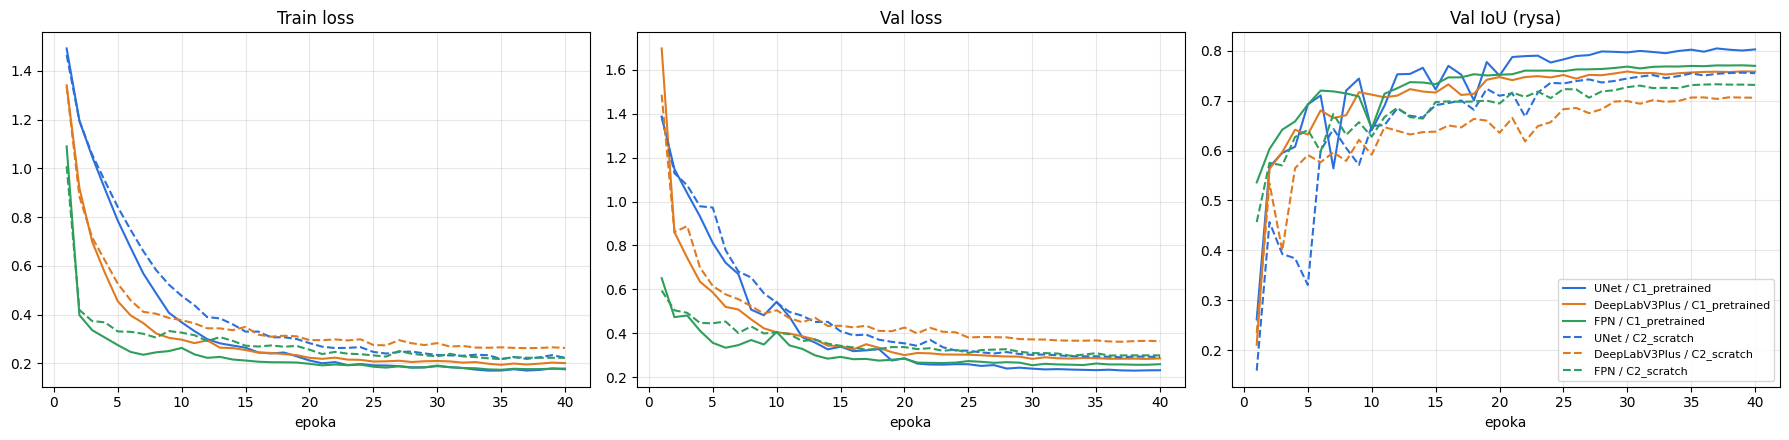

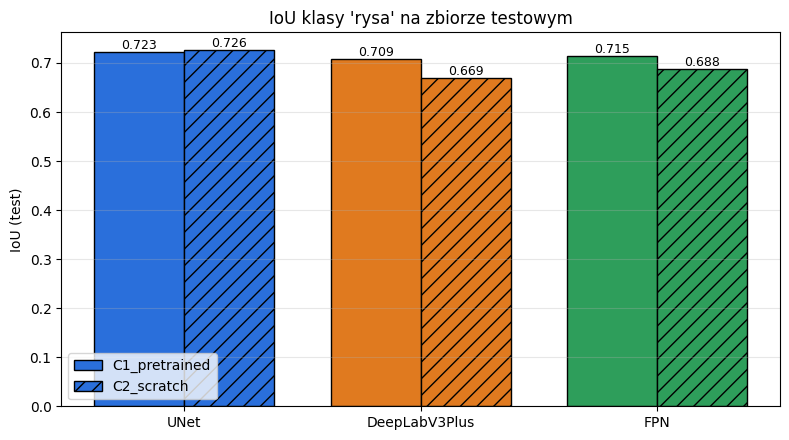

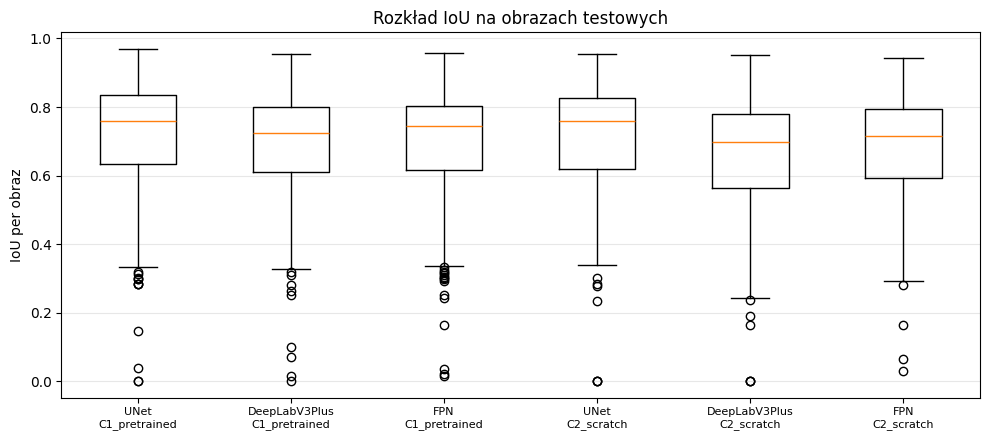

In [15]:
COLORS = {"UNet": "#2a6fdb", "DeepLabV3Plus": "#e07a1f", "FPN": "#2e9e5b"}

# 11.1 Krzywe uczenia
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for cfg_name, ls in zip(CONFIGS, ["-", "--"]):
    for arch in ARCHS:
        h = pd.read_csv(OUT_DIR / f"{arch}__{cfg_name}" / "history.csv")
        lab = f"{arch} / {cfg_name}"
        ax[0].plot(h.epoch, h.train_loss, ls, color=COLORS[arch], label=lab)
        ax[1].plot(h.epoch, h.val_loss, ls, color=COLORS[arch], label=lab)
        ax[2].plot(h.epoch, h.val_iou, ls, color=COLORS[arch], label=lab)
for a, t in zip(ax, ["Train loss", "Val loss", "Val IoU (rysa)"]):
    a.set_title(t); a.set_xlabel("epoka"); a.grid(alpha=.3)
ax[2].legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT_DIR / "learning_curves.png", dpi=150); plt.show()

# 11.2 Porównanie IoU na teście
fig, ax = plt.subplots(figsize=(8, 4.5))
archs = list(ARCHS); w = 0.38; xs = np.arange(len(archs))
for k, (cfg_name, hatch) in enumerate(zip(CONFIGS, ["", "//"])):
    vals = [results_df.query("architektura==@a and konfiguracja==@cfg_name").test_IoU.item() for a in archs]
    bars = ax.bar(xs + (k - .5) * w, vals, w, color=[COLORS[a] for a in archs], hatch=hatch,
                  edgecolor="black", label=cfg_name)
    ax.bar_label(bars, fmt="%.3f", fontsize=9)
ax.set_xticks(xs, archs); ax.set_ylabel("IoU (test)"); ax.set_title("IoU klasy 'rysa' na zbiorze testowym")
ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); fig.savefig(OUT_DIR / "test_iou_bar.png", dpi=150); plt.show()

# 11.3 Rozkład IoU per obraz
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([per_image_df[c] for c in per_image_df.columns])
ax.set_xticks(range(1, len(per_image_df.columns) + 1), [c.replace("__", "\n") for c in per_image_df.columns])
ax.set_ylabel("IoU per obraz"); ax.set_title("Rozkład IoU na obrazach testowych"); ax.grid(axis="y", alpha=.3)
plt.xticks(fontsize=8); plt.tight_layout(); fig.savefig(OUT_DIR / "per_image_iou_box.png", dpi=150); plt.show()

## 12. Przykładowe predykcje: obraz | maska prawdziwa | 3 modele
Pokazujemy przypadki typowe (mediana IoU), najlepsze i **najgorsze** (gdzie modele się mylą).
Kolory nakładki: **zielony** = TP, **czerwony** = FP (fałszywa rysa), **niebieski** = FN (przeoczona rysa).

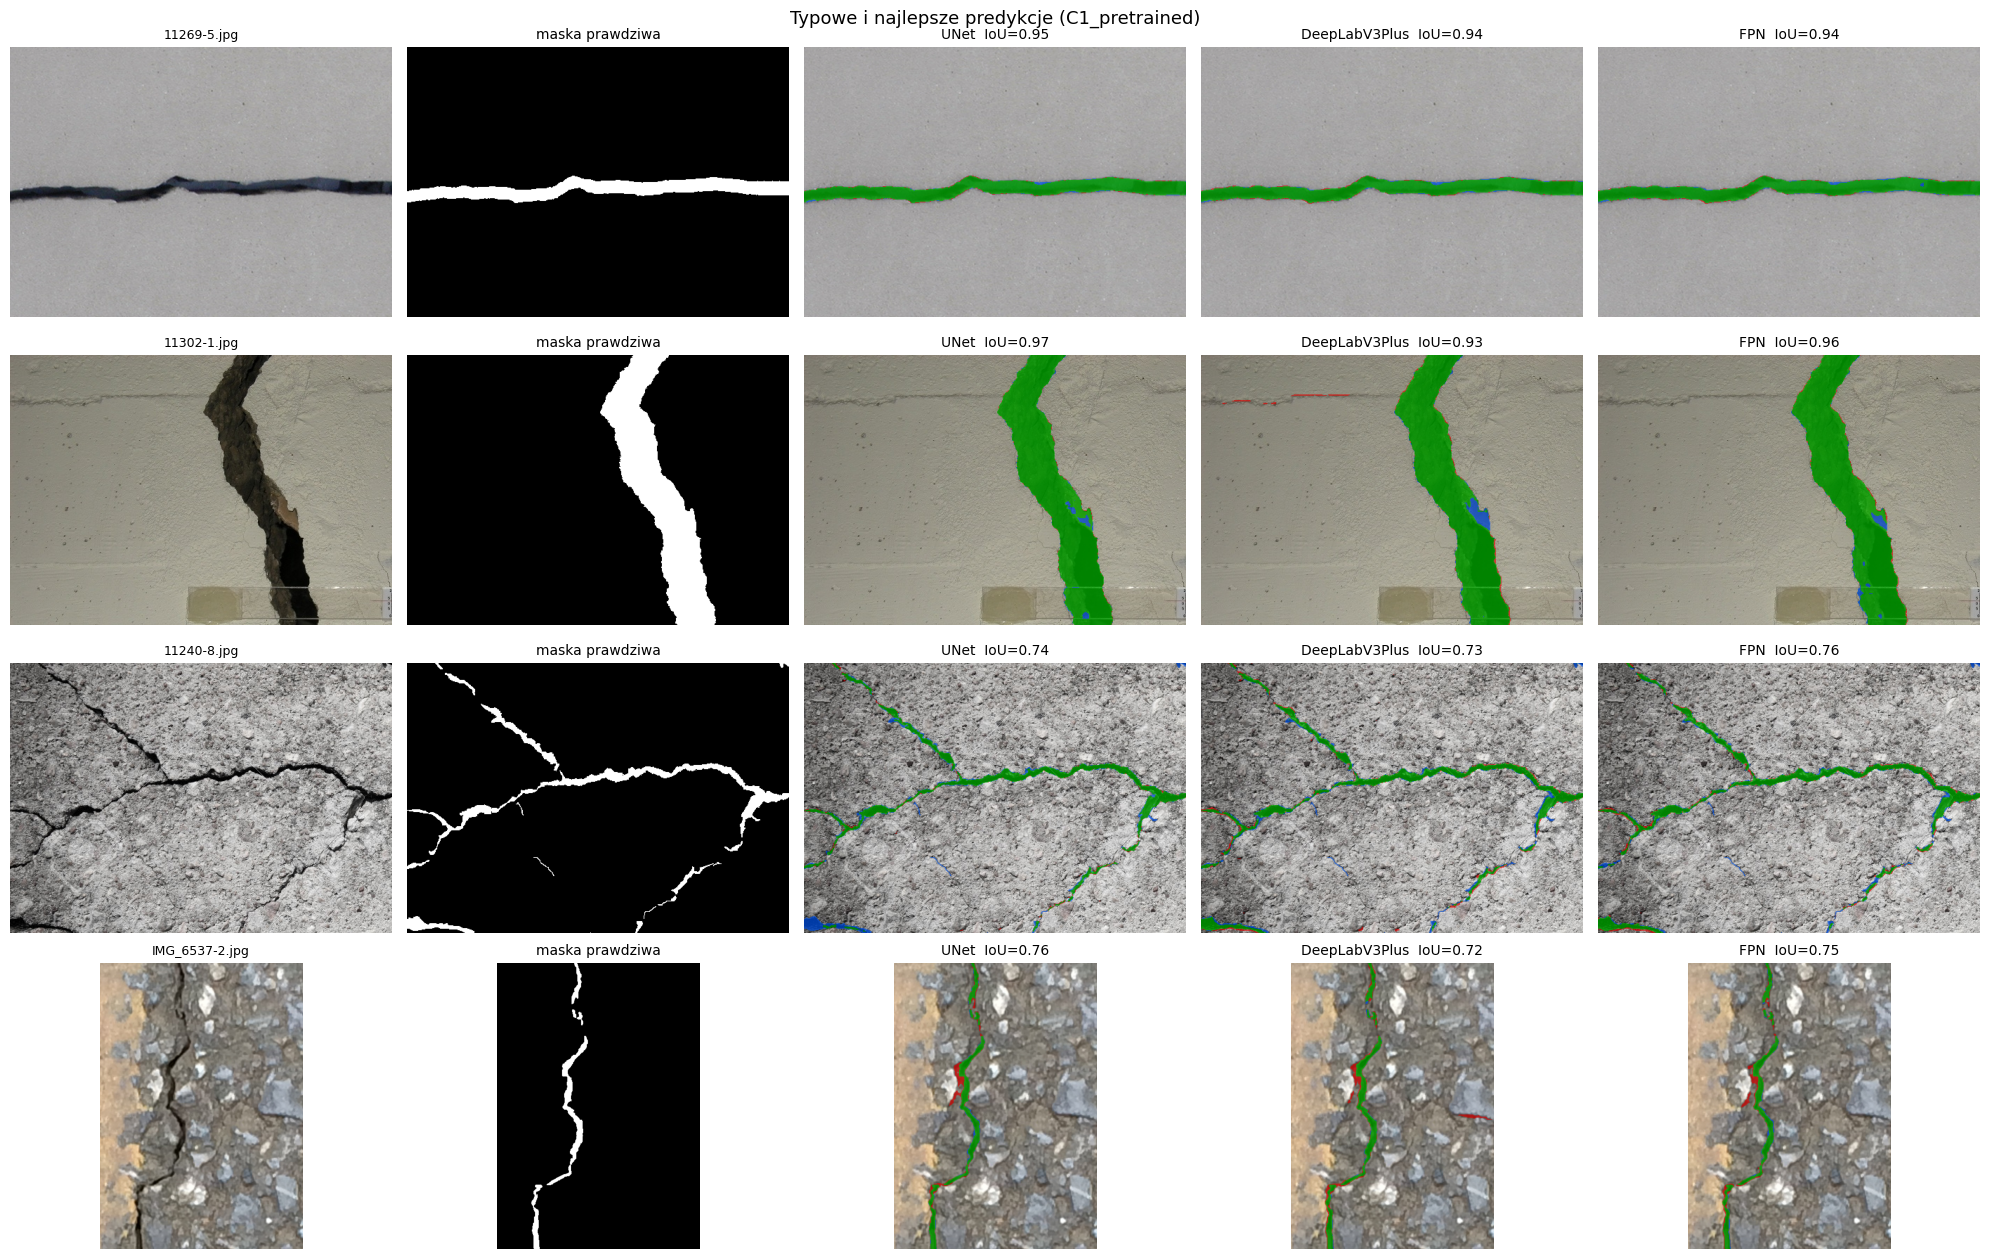

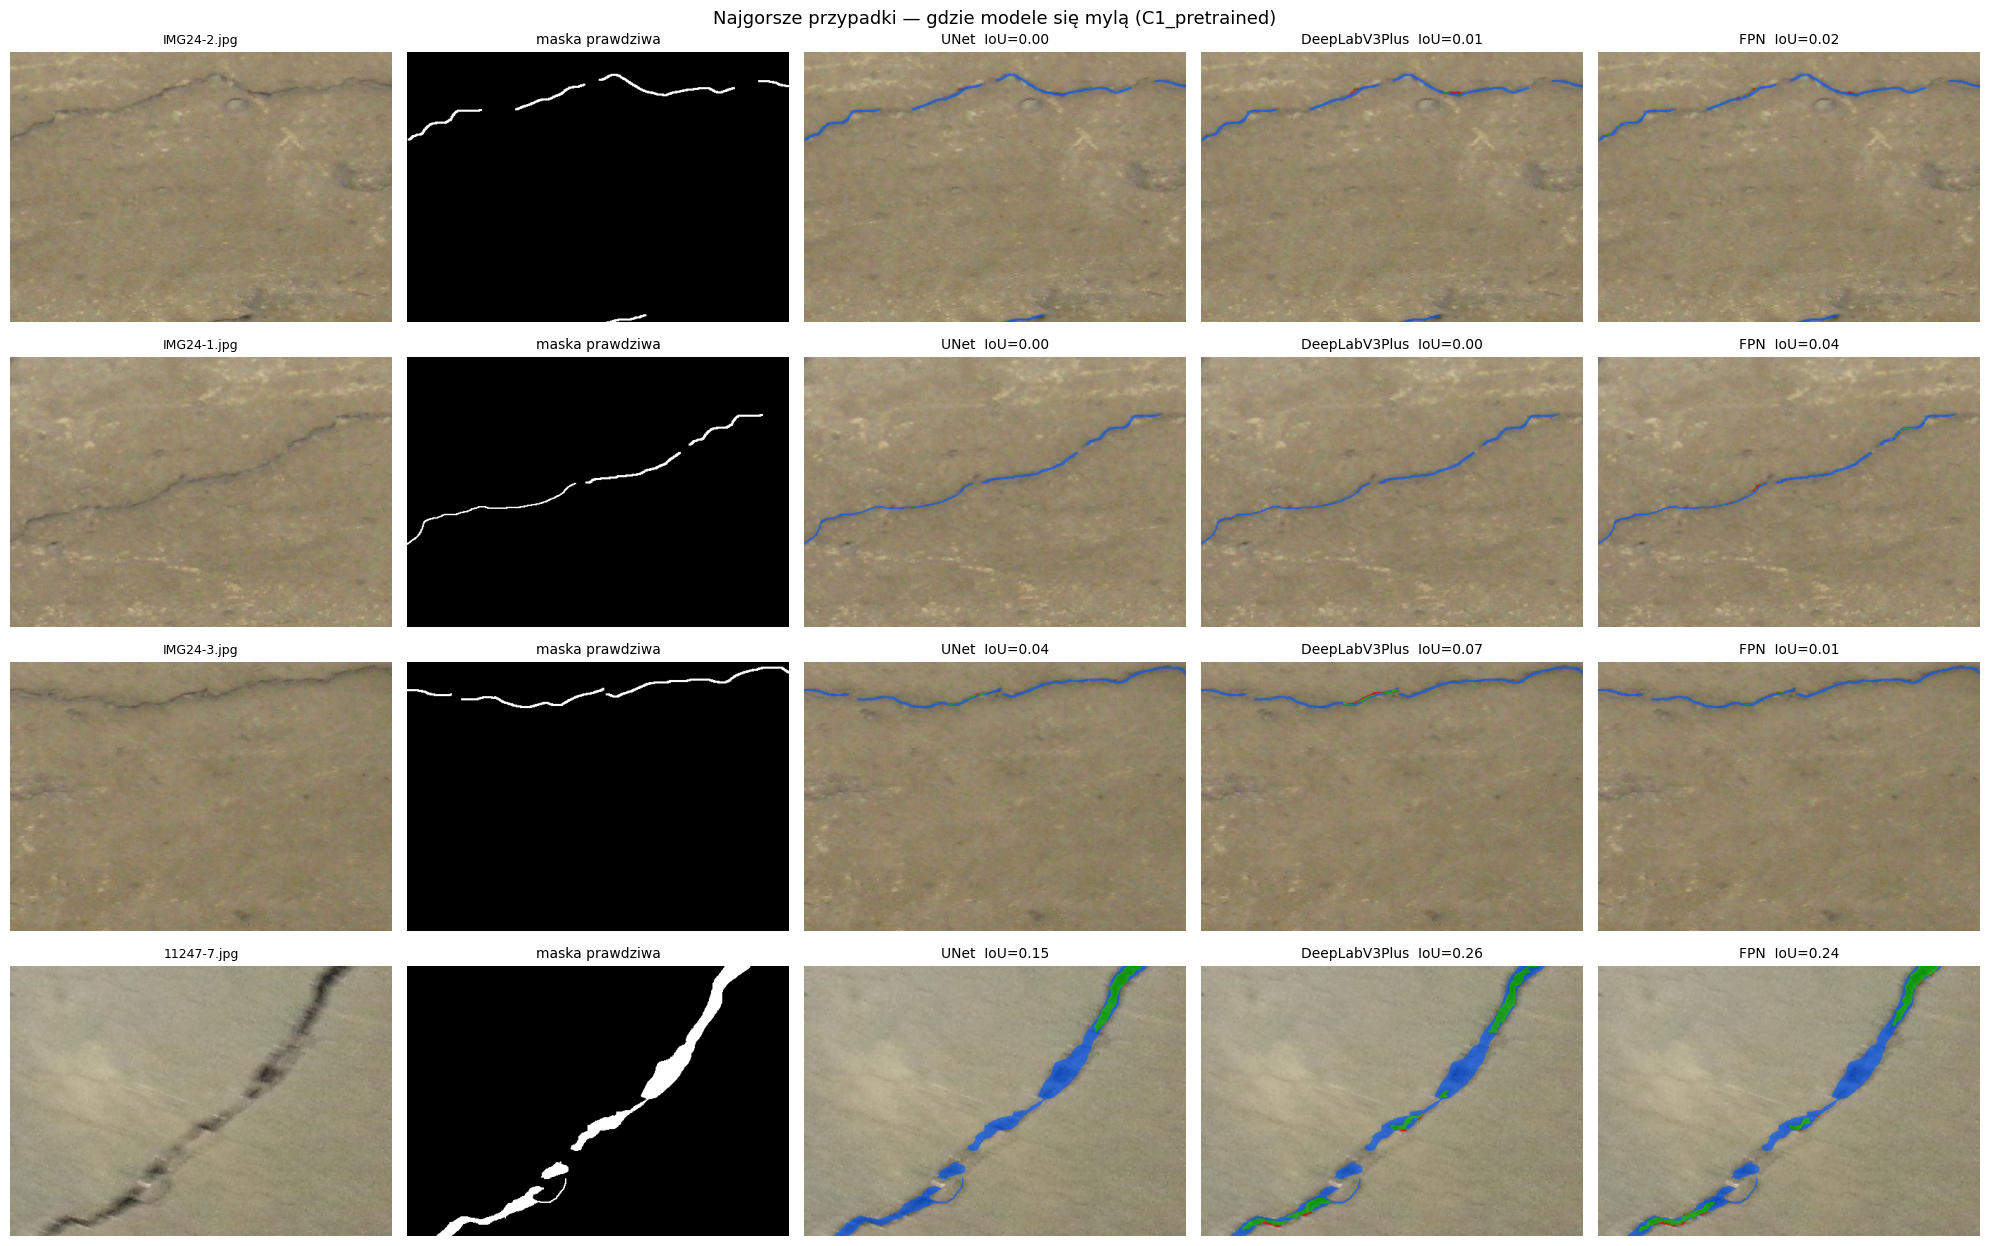

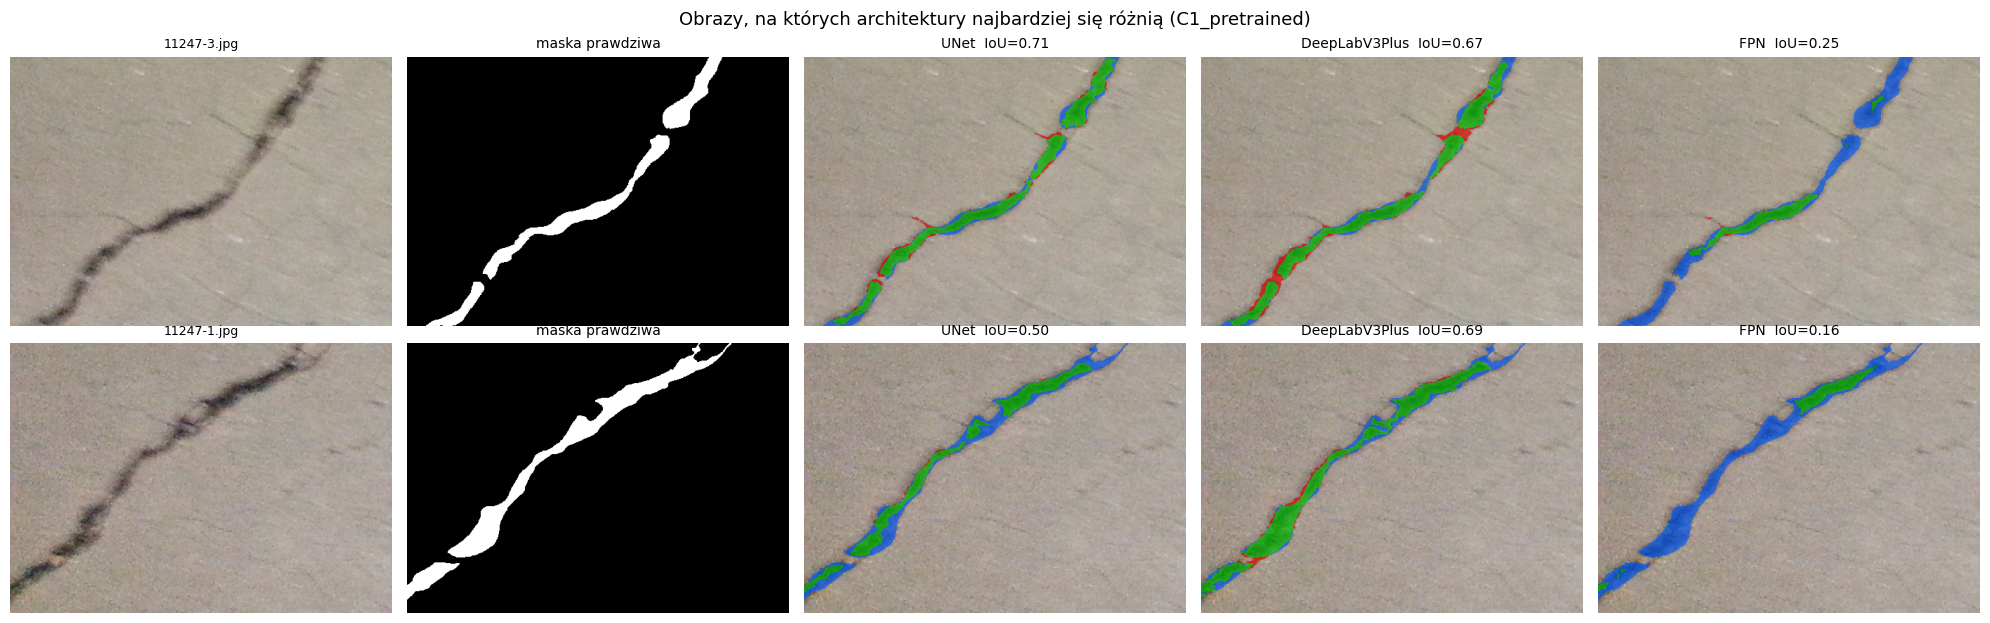

In [16]:
def overlay(img, gt, pred):
    o = img.copy().astype(np.float32)
    colors = {(1, 1): (0, 200, 0), (0, 1): (230, 0, 0), (1, 0): (0, 90, 255)}
    for (g, p), c in colors.items():
        sel = (gt == g) & (pred == p)
        o[sel] = 0.35 * o[sel] + 0.65 * np.array(c)
    return o.clip(0, 255).astype(np.uint8)

@torch.no_grad()
def predict(model, name):
    r = split_df[(split_df.split == "test") & (split_df.image.str.endswith(name))].iloc[0]
    img = cv2.cvtColor(cv2.imread(r["image"]), cv2.COLOR_BGR2RGB)
    gt = (cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    x = get_transforms(False)(image=img)["image"].unsqueeze(0).to(DEVICE)
    pred = (torch.sigmoid(model(x))[0, 0].cpu().numpy() > 0.5).astype(np.uint8)
    return img, gt, pred

def prediction_grid(cfg_name, names, title, fname):
    models = {a: load_run(f"{a}__{cfg_name}")[0] for a in ARCHS}
    fig, ax = plt.subplots(len(names), 2 + len(models), figsize=(4 * (2 + len(models)), 3.2 * len(names)))
    ax = np.atleast_2d(ax)
    for i, n in enumerate(names):
        for j, (arch, m) in enumerate(models.items()):
            img, gt, pred = predict(m, n)
            iou = per_image_df.loc[n, f"{arch}__{cfg_name}"]
            ax[i, 2 + j].imshow(overlay(img, gt, pred)); ax[i, 2 + j].set_title(f"{arch}  IoU={iou:.2f}", fontsize=10)
        ax[i, 0].imshow(img); ax[i, 0].set_title(n, fontsize=9)
        ax[i, 1].imshow(gt, cmap="gray"); ax[i, 1].set_title("maska prawdziwa", fontsize=10)
        for a in ax[i]: a.axis("off")
    fig.suptitle(title, fontsize=13); plt.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=130); plt.show()
    del models; torch.cuda.empty_cache()

best_cfg = results_df.groupby("konfiguracja").test_IoU.mean().idxmax()
cols = [f"{a}__{best_cfg}" for a in ARCHS]
mean_iou = per_image_df[cols].mean(axis=1).sort_values()
worst = mean_iou.index[:4].tolist()
median = mean_iou.index[len(mean_iou) // 2 - 1: len(mean_iou) // 2 + 1].tolist()
best = mean_iou.index[-2:].tolist()
disagree = per_image_df[cols].std(axis=1).sort_values().index[-2:].tolist()   # modele najbardziej się różnią

prediction_grid(best_cfg, best + median, f"Typowe i najlepsze predykcje ({best_cfg})", "pred_good.png")
prediction_grid(best_cfg, worst, f"Najgorsze przypadki — gdzie modele się mylą ({best_cfg})", "pred_worst.png")
prediction_grid(best_cfg, disagree, f"Obrazy, na których architektury najbardziej się różnią ({best_cfg})", "pred_disagree.png")

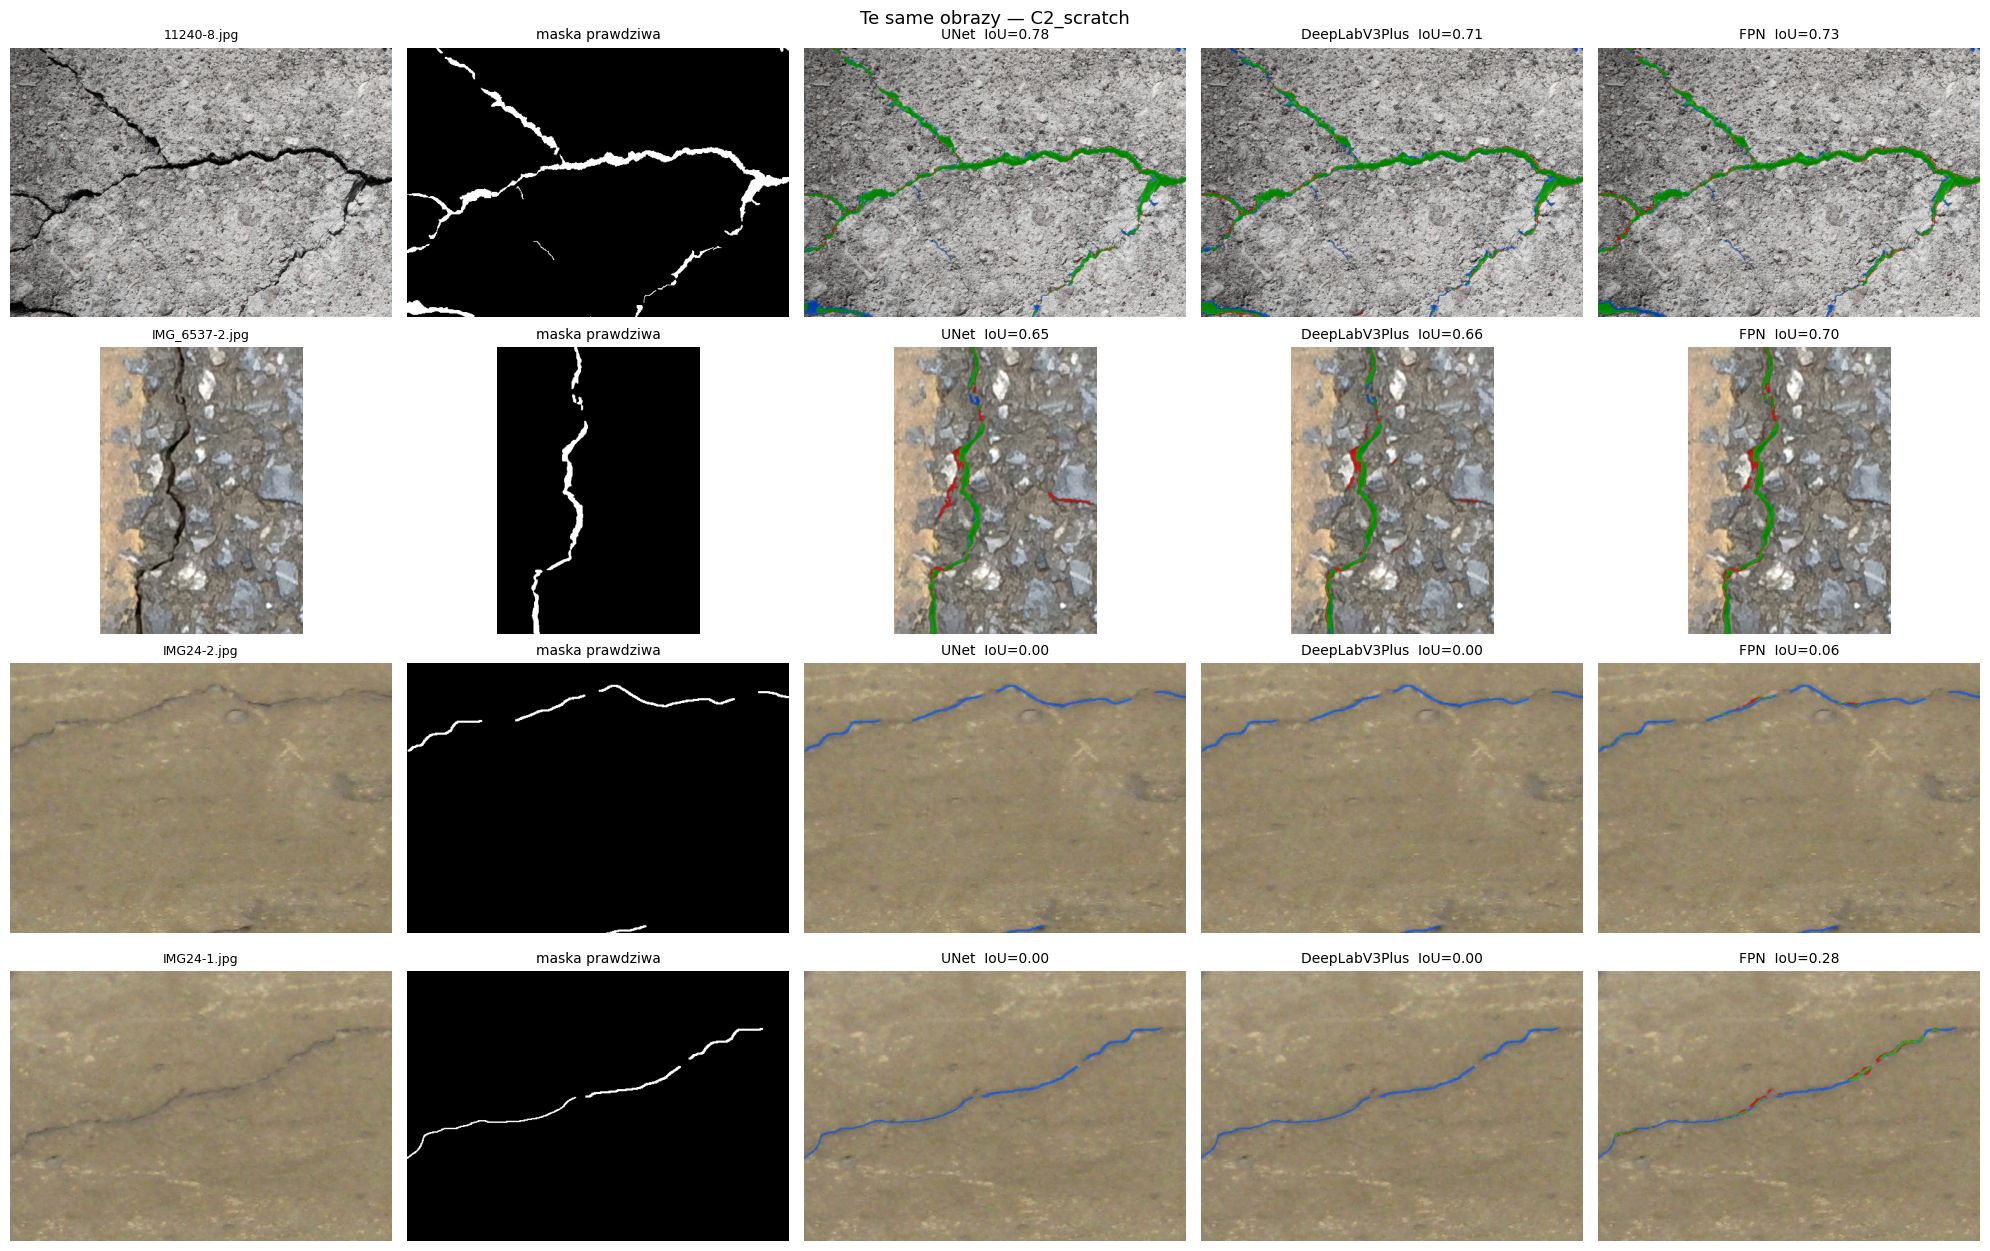

In [17]:
# Te same obrazy dla konfiguracji 2 — bezpośrednie porównanie efektu zmiany
other_cfg = [c for c in CONFIGS if c != best_cfg][0]
prediction_grid(other_cfg, median + worst[:2], f"Te same obrazy — {other_cfg}", "pred_other_cfg.png")

## 13. Wnioski
1. **Najlepsza architektura:** U-Net — test IoU 0,726 (od zera) i 0,723 (z pretreningiem), F1 0,841 / 0,840. Różnica 0,3 pp mieści się w szumie jednego seeda.
2. **Hipotezy (tabela 10a):**
   - H1 (pretrening pomaga wszystkim) — **częściowo potwierdzona**: bez pretreningu DeepLabV3+ traci 3,97 pp IoU, FPN 2,69 pp, a U-Net zyskuje 0,28 pp.
   - H2 (największy spadek u DeepLabV3+) — **potwierdzona**.
   - H3 (U-Net i FPN > DeepLabV3+ w konf. 1) — kierunek zgodny (0,723 > 0,715 > 0,709), ale rozrzut 1,4 pp jest w granicach szumu.
   - H4 (od zera: wolniejsza zbieżność, niższy recall) — **częściowo potwierdzona**: zbieżność wolniejsza, recall niższy u DeepLabV3+ i FPN, u U-Neta nie.
3. **Precision vs recall:** we wszystkich 6 treningach precision (0,87–0,91) > recall (0,74–0,79) — modele częściej przeoczają rysy, niż wykrywają fałszywe.
4. **Najczęstsze błędy (sekcja 12):** najcieńsze odgałęzienia rys, szczeliny między kruszywem w asfalcie mylone z rysą, rozmyte zdjęcia. Trzy najgorsze obrazy to seria IMG24 (gładki tynk, niski kontrast), której nie ma w zbiorze treningowym: z pretreningiem IoU ≤ 0,07 dla wszystkich modeli.
5. **Ograniczenia:** jeden seed na trening, walidacja (60 obrazów) różni się od testu (val IoU wyższe o 3–8 pp), próg 0,5 nie był dobierany, IoU bardzo surowe dla rys szerokich na 2–3 px.
6. **Co dalej:** 3–5 seedów (średnia ± odchylenie), F1 z tolerancją 2–3 px, podział danych uwzględniający serie zdjęć, dobór progu na walidacji, test na innym zbiorze (np. dacl10k).

In [ ]:
# Lista zapisanych plików wynikowych
for p in sorted(OUT_DIR.glob("*.png")) + sorted(OUT_DIR.glob("*.csv")):
    print(p)